# EDA 04. Feature Overlap and Selection

CRISP-DM phase: Data preparation

Notebooks 02 and 03 checked which features carry a signal. Some of the features are near copies of each other, and a model does not need both. This notebook finds those copies, keeps one feature from each group and saves the final list of features to `data/processed/selected_features.csv` (names only, no data, so it can be committed). Only the training rows are used.

## 1. Setup and Data Loading

### 1.1 Importing Libraries

In [1]:
#necessary imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

### 1.2 Loading the Dataset

In [2]:
#loading the full model table (pcode is kept as text)
df = pd.read_csv('../../data/private/model_table_full.csv', dtype={'pcode': str})

In [3]:
#keeping the training rows: July 2002 to December 2019
df['year_month'] = df['year'] * 100 + df['month']
train = df[(df['year_month'] >= 200207) & (df['year_month'] <= 201912)].copy()
train.shape

(9870, 71)

## 2. The Candidate Features

The candidates are all the columns a model could use. The target, `flood_this_month` (the baseline), `heavy_rain_next_month`, `desinventar_no_record_year`, the label and source columns and the keys (`pcode`, `county`, `year`, `month`) are never features, so they are left out.

In [4]:
#the candidate features, by group
rain = ['rain_mm', 'rain_max_dekad', 'rain_lag1', 'rain_lag2', 'rain_3mo_total', 'rain_pct_normal', 'neighbour_rain', 'neighbour_rain_lag1']
vegetation = ['ndvi', 'ndvi_pct_normal']
ocean = ['oni', 'oni_lag1', 'oni_lag2', 'oni_lag3', 'dmi', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3']
calendar = ['month_sin', 'month_cos']
soil_and_rivers = ['soil_moisture_l1', 'soil_moisture_l1_lag1', 'soil_moisture_l2', 'soil_moisture_l2_lag1', 'runoff_rank', 'discharge_rank', 'discharge_rank_lag1']
terrain = ['elevation', 'elev_std', 'slope', 'pct_flat', 'area_km2']
land_cover = ['lc_tree', 'lc_shrub', 'lc_grass', 'lc_crop', 'lc_built', 'lc_bare', 'lc_water', 'lc_wetland', 'lc_mangrove']
water = ['pct_within_1km_river', 'pct_within_5km_river', 'pct_within_1km_water', 'pct_water', 'pct_occasional_water']
people = ['pop_density', 'pct_built']
history = ['county_flood_rate']
candidates = rain + vegetation + ocean + calendar + soil_and_rivers + terrain + land_cover + water + people + history
len(candidates)

49

#### Observation

There are 49 candidate features: 8 rain, 2 vegetation, 8 ocean, 2 calendar, 7 soil and river, 5 terrain, 9 land cover, 5 water, 2 people and 1 flood history. `season` is not a candidate, because `month_sin` and `month_cos` already give the time of year.

## 3. Correlation Between the Candidates

The correlation `r` goes from -1 to +1. Close to +1 or -1 means two features move together almost perfectly, so they carry the same information.

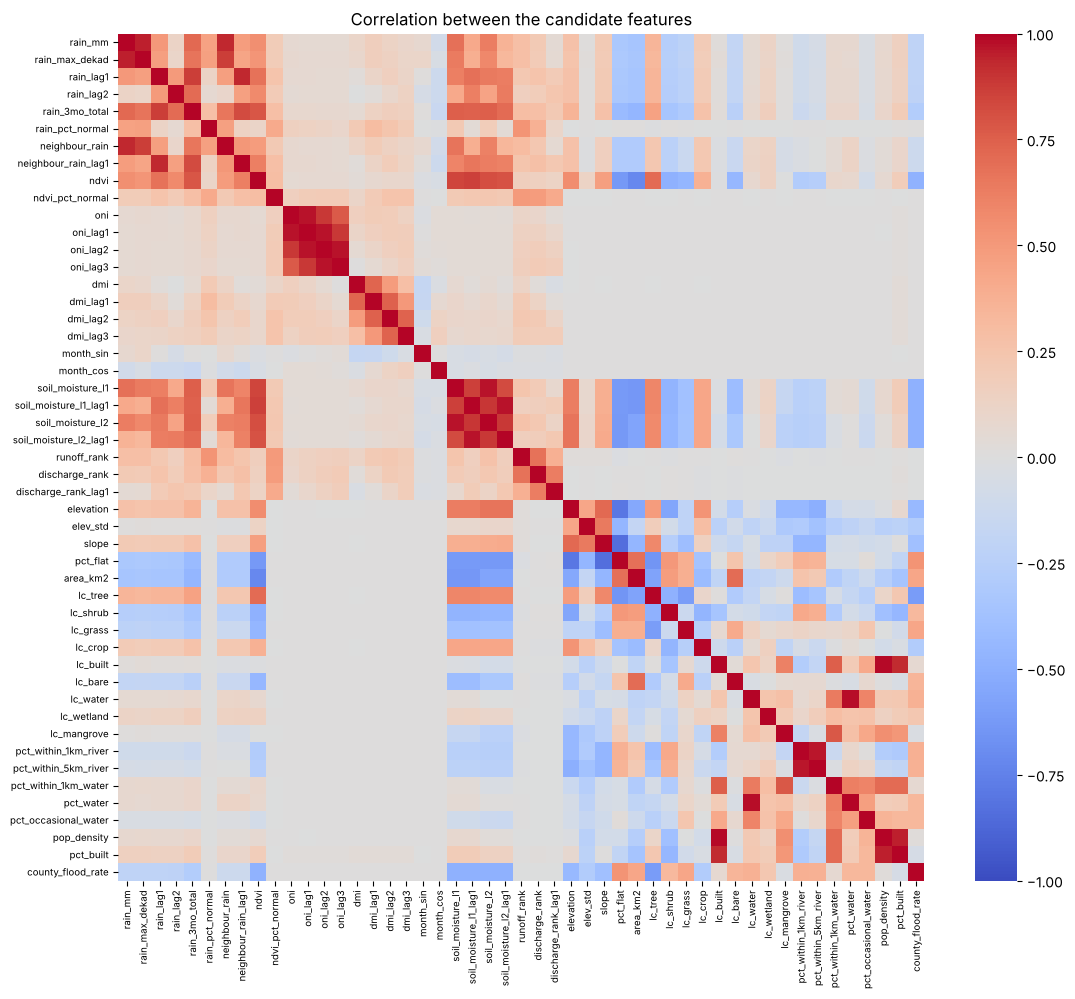

In [5]:
#correlation between every pair of candidates
corr = train[candidates].corr()

plt.figure(figsize=(13, 11))
sns.heatmap(corr, cmap='coolwarm', center=0, vmin=-1, vmax=1, xticklabels=True, yticklabels=True)
plt.xticks(fontsize=7)
plt.yticks(fontsize=7)
plt.title('Correlation between the candidate features')
plt.show()

#### Observation

The dark red squares along the diagonal are groups of features that move together: the ONI lags, the soil moisture columns, the rain columns, and the built-up and population columns. Features such as `rain_pct_normal`, `runoff_rank`, `ndvi_pct_normal`, `month_sin` and `month_cos` are pale against almost everything, so they carry their own information.

In [6]:
#pairs of candidates with a correlation above 0.8 or below -0.8
#(a < b makes sure each pair is listed only once)
pairs = []
for a in candidates:
    for b in candidates:
        if a < b and abs(corr.loc[a, b]) > 0.8:
            pairs.append([a, b, round(corr.loc[a, b], 3)])
pairs = pd.DataFrame(pairs, columns=['feature A', 'feature B', 'r'])
pairs.sort_values('r', ascending=False)

,feature A,feature B,r
22,lc_built,pop_density,0.985
24,lc_water,pct_water,0.984
18,soil_moisture_l1_lag1,soil_moisture_l2_lag1,0.975
15,soil_moisture_l1,soil_moisture_l2,0.975
9,oni,oni_lag1,0.969
13,oni_lag2,oni_lag3,0.969
11,oni_lag1,oni_lag2,0.969
25,pct_within_1km_river,pct_within_5km_river,0.965
26,pct_built,pop_density,0.951
0,rain_max_dekad,rain_mm,0.950


#### Observation

27 pairs have a correlation above 0.8 or below -0.8. The closest copies are `lc_built` and `pop_density` (0.985), `lc_water` and `pct_water` (0.984), the two soil layers (0.975), the ONI lags (0.886 to 0.969), the 1 km and 5 km river shares (0.965), and `rain_mm` with `rain_max_dekad` (0.950) and with `neighbour_rain` (0.934). The only negative pairs are `pct_flat` with `slope` (-0.844) and with `elevation` (-0.800). Raw `ndvi` is also close to the soil columns (0.818 to 0.859).

## 4. Does the Second Feature Add Anything?

Two features can be highly correlated and the second one can still add a little. To check, we fit a straight line from feature A to feature B with `np.polyfit` and keep what is left of B that A cannot explain (the leftover). If the AUC of the leftover is close to 0.5, B adds nothing once A is known.

In [7]:
#rain_max_dekad after taking out rain_mm
slope, intercept = np.polyfit(train['rain_mm'], train['rain_max_dekad'], 1)
leftover = train['rain_max_dekad'] - (slope * train['rain_mm'] + intercept)
roc_auc_score(train['flood_next_month'], leftover)

0.512311073368674

In [8]:
#neighbour_rain after taking out rain_mm
slope, intercept = np.polyfit(train['rain_mm'], train['neighbour_rain'], 1)
leftover = train['neighbour_rain'] - (slope * train['rain_mm'] + intercept)
roc_auc_score(train['flood_next_month'], leftover)

0.6309807634669354

In [9]:
#dmi_lag1 after taking out dmi
slope, intercept = np.polyfit(train['dmi'], train['dmi_lag1'], 1)
leftover = train['dmi_lag1'] - (slope * train['dmi'] + intercept)
roc_auc_score(train['flood_next_month'], leftover)

0.530346521489474

#### Observation

After taking out `rain_mm`, the leftover of `rain_max_dekad` has an AUC of 0.512, so it adds nothing and can be dropped. The leftover of `dmi_lag1` after `dmi` has 0.530, which is very little. `neighbour_rain` is different: its leftover after `rain_mm` still has an AUC of 0.631, so the rain in the surrounding counties tells us something the county's own rain does not, even though the two are correlated at 0.934. Both are kept.

## 5. One Feature per Group

For each group of near copies we keep the feature with the stronger signal in notebooks 02 and 03, or the clearer meaning.

| group | members | largest r | keep | reason |
|---|---|---|---|---|
| rain level | `rain_mm`, `rain_max_dekad` | 0.950 | `rain_mm` | `rain_max_dekad` adds nothing (leftover AUC 0.512) |
| neighbours' rain | `rain_mm`, `neighbour_rain` | 0.934 | both | `neighbour_rain` adds signal (leftover AUC 0.631) |
| rain lags | `rain_lag1`, `neighbour_rain_lag1`, `rain_3mo_total` | 0.933 | `rain_lag1` | the other two had no signal in notebook 02 |
| ONI | `oni` and its three lags | 0.969 | `oni` | the lags are near copies |
| DMI | `dmi` and its three lags | 0.746 | `dmi` | the lags add very little (leftover AUC 0.530) |
| vegetation | `ndvi`, `ndvi_pct_normal` | 0.29 | `ndvi_pct_normal` | raw `ndvi` mostly describes the county and repeats soil moisture |
| soil | the two layers and their lags | 0.975 | `soil_moisture_l1` | the top layer reacts first, the rest repeat it |
| river flow | `discharge_rank`, `discharge_rank_lag1` | 0.63 | `discharge_rank` | the lag has no signal |
| relief | `pct_flat`, `slope`, `elevation` | -0.844 | `pct_flat` | the strongest of the three in notebook 03 |
| people and built land | `pop_density`, `pct_built`, `lc_built` | 0.985 | `pop_density` | same information, clearest meaning |
| water bodies | `pct_water`, `lc_water` | 0.984 | `pct_water` | same quantity from two maps |
| rivers | `pct_within_1km_river`, `pct_within_5km_river` | 0.965 | 1 km | the 5 km share is a wider copy |

`elev_std`, `lc_shrub`, `lc_wetland`, `lc_mangrove` and `pct_within_1km_water` are also dropped, because they had no clear relation with the flood rate in notebook 03 (`lc_shrub` was the weakest of the land-cover shares).

## 6. The Final List

In [10]:
#the kept features
selected = ['rain_mm', 'rain_lag1', 'rain_lag2', 'rain_pct_normal', 'neighbour_rain',
            'ndvi_pct_normal', 'oni', 'dmi', 'month_sin', 'month_cos',
            'soil_moisture_l1', 'runoff_rank', 'discharge_rank',
            'pct_flat', 'area_km2', 'lc_tree', 'lc_grass', 'lc_crop', 'lc_bare',
            'pct_within_1km_river', 'pct_water', 'pct_occasional_water', 'pop_density',
            'county_flood_rate']
len(selected)

24

In [11]:
#the dropped candidates
dropped = []
for f in candidates:
    if f not in selected:
        dropped.append(f)
print(len(dropped))
print(dropped)

25
['rain_max_dekad', 'rain_3mo_total', 'neighbour_rain_lag1', 'ndvi', 'oni_lag1', 'oni_lag2', 'oni_lag3', 'dmi_lag1', 'dmi_lag2', 'dmi_lag3', 'soil_moisture_l1_lag1', 'soil_moisture_l2', 'soil_moisture_l2_lag1', 'discharge_rank_lag1', 'elevation', 'elev_std', 'slope', 'lc_shrub', 'lc_built', 'lc_water', 'lc_wetland', 'lc_mangrove', 'pct_within_5km_river', 'pct_within_1km_water', 'pct_built']


In [12]:
#pairs of kept features that are still above 0.8 or below -0.8
for a in selected:
    for b in selected:
        if a < b and abs(corr.loc[a, b]) > 0.8:
            print(a, b, round(corr.loc[a, b], 3))

neighbour_rain rain_mm 0.934


#### Observation

24 features are kept and 25 candidates are dropped. The only pair of kept features still above 0.8 is `neighbour_rain` and `rain_mm` (0.934), which is kept on purpose because of the leftover test in Section 4.

In [13]:
#saving the names of the kept features (names only, no data)
pd.DataFrame({'feature': selected}).to_csv('../../data/processed/selected_features.csv', index=False)

In [14]:
#checking the saved file
pd.read_csv('../../data/processed/selected_features.csv').shape

(24, 1)

#### Observation

The saved file has 24 rows and one column `feature`, with the names of the kept features only. It contains no data, so it can be committed to GitHub.

## 7. Summary

The 49 candidates become 24 features:
- rain: `rain_mm`, `rain_lag1`, `rain_lag2`, `rain_pct_normal`, `neighbour_rain`
- vegetation: `ndvi_pct_normal`
- ocean: `oni`, `dmi`
- calendar: `month_sin`, `month_cos`
- soil and rivers: `soil_moisture_l1`, `runoff_rank`, `discharge_rank`
- place: `pct_flat`, `area_km2`, `lc_tree`, `lc_grass`, `lc_crop`, `lc_bare`, `pct_within_1km_river`, `pct_water`, `pct_occasional_water`, `pop_density`
- flood history: `county_flood_rate`

The dropped features are near copies of a kept feature or had no clear signal. Points for the modelling notebooks: `county_flood_rate` must be recalculated from past months inside each training fold; the raw `soil_moisture_l1` mixes place and weather, so a county-month anomaly may work better; `oni` and `neighbour_rain` are the first features to drop if the models are unstable; and the place features rest on only 47 counties, so the models should be checked with folds grouped by county.